# 01 · A first look at the world's fires

> **What and why**
>
> - We count the fires each satellite saw, every year, all over the world.
> - We compare two cameras that pass over at the same time of day, to see how different they really are.
> - We check whether the gap between them is one number or many.
> - These facts decide how the harmonization has to work.

In [1]:
import sys, os
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'style'))
import pandas as pd, numpy as np, duckdb, matplotlib.pyplot as plt
import fireharmony_style as fh
from fireharmony import config as C, features as FE
fh.use(); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = REPO / 'report' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
con = C.connect()
from fireharmony import aggregate as AG
GOLD = [str(AG.gold_path(y)) for y in C.years() if AG.gold_path(y).exists()]
STATIC = C.work('features', 'cell_static_l5.parquet')

## 1. Fires per year, satellite by satellite

A hotspot is one pixel that a satellite marked as unusually hot. We count vegetation fires only, with the main confidence rule. We show each satellite on its own. MODIS flies on two satellites (Terra and Aqua), so we use their average, which makes one MODIS satellite comparable with one VIIRS satellite.

satellite,MODIS,Suomi-NPP,NOAA-20,NOAA-21
yr,,,,
2012,2.27,NaN,NaN,NaN
2013,1.93,15.72,NaN,NaN
2014,2.01,16.68,NaN,NaN
2015,2.16,17.68,NaN,NaN
2016,2.01,16.63,NaN,NaN
2017,2.02,16.32,NaN,NaN
2018,1.90,15.56,NaN,NaN
2019,2.09,17.31,16.96,NaN
2020,2.03,17.08,16.81,NaN


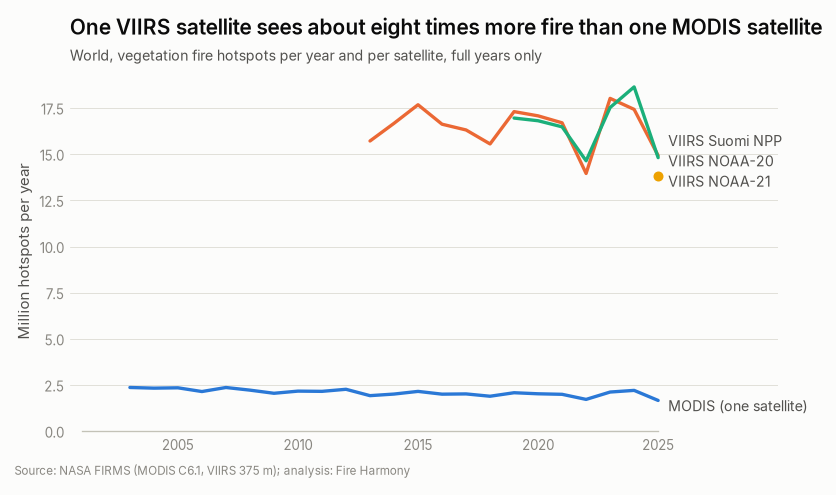

In [2]:
yearly = con.execute(f'''
  SELECT yr, satellite, sum(n_main) AS n FROM read_parquet({GOLD}) WHERE yr BETWEEN 2001 AND 2025 GROUP BY ALL''').df()
w = yearly.pivot(index='yr', columns='satellite', values='n')
w['MODIS'] = w[['Terra', 'Aqua']].mean(axis=1, skipna=False)          # one MODIS satellite: only years with both
lines = {'MODIS': 'MODIS', 'Suomi-NPP': 'VIIRS_SNPP', 'NOAA-20': 'VIIRS_NOAA20', 'NOAA-21': 'VIIRS_NOAA21'}
first_full = {'MODIS': 2003, 'Suomi-NPP': 2013, 'NOAA-20': 2019, 'NOAA-21': 2025}   # first full year of each satellite
for col, y0 in first_full.items():
    w.loc[w.index < y0, col] = np.nan                                    # partial years would fake a dip
fig, ax = plt.subplots(figsize=fh.SIZE['full'])
ends = []
for col, key in lines.items():
    s = w[col].dropna() / 1e6
    ax.plot(s.index, s.values, color=fh.SENSOR[key], lw=2, marker='o' if len(s) == 1 else None, ms=5)
    ends.append((s.index[-1], s.values[-1], fh.SENSOR_LABEL[key].replace(' (Terra + Aqua)', ' (one satellite)')))
fh.label_ends(ax, ends, gap=1.1)
fh.clean(ax); ax.set_xlim(2000.5, 2030); ax.set_ylim(0, None); ax.set_ylabel('Million hotspots per year'); fh.year_axis(ax, 2001, 2025)
fh.title(ax, 'One VIIRS satellite sees about eight times more fire than one MODIS satellite', 'World, vegetation fire hotspots per year and per satellite, full years only')
fh.source(fig, 'Source: NASA FIRMS (MODIS C6.1, VIIRS 375 m); analysis: Fire Harmony')
fh.save(fig, FIG / 'fig01_fires_per_satellite')
(w[list(lines)] / 1e6).round(2).tail(14)

## 2. Same time of day, two cameras

Aqua (MODIS) and Suomi NPP (VIIRS) both cross the equator at about 1:30 in the afternoon. So when we compare them, time of day and weather are the same. Only the camera differs.

In [3]:
cmp = con.execute(f'''
  SELECT satellite, sum(n_main) AS n, sum(n_day) AS n_d, sum(n_night) AS n_n, sum(n_small) AS n_s
  FROM read_parquet({GOLD}) WHERE yr BETWEEN 2013 AND 2019 AND satellite IN ('Aqua', 'Suomi-NPP') GROUP BY 1''').df().set_index('satellite')
ratio = (cmp.loc['Suomi-NPP'] / cmp.loc['Aqua'])[['n', 'n_d', 'n_n']].round(1)
small = (100 * cmp['n_s'] / cmp['n']).round(1)
print(f"VIIRS / MODIS, same afternoon pass: all {ratio['n']}x, day {ratio['n_d']}x, night {ratio['n_n']}x")
print(f"weak fires (below 5 MW): Suomi NPP {small['Suomi-NPP']}%, Aqua {small['Aqua']}%")

VIIRS / MODIS, same afternoon pass: all 6.1x, day 5.0x, night 30.6x
weak fires (below 5 MW): Suomi NPP 46.1%, Aqua 0.9%


## 3. The gap depends on the land

We group the hexagon cells by their main land cover and compute the same ratio for each group.

,lc_main,ratio,viirs
0,savanna,5.74,59763049.0
1,forest,5.97,17582376.0
2,grassland,6.61,22953635.0
3,cropland,6.97,10791760.0
4,shrubland,8.26,2869847.0


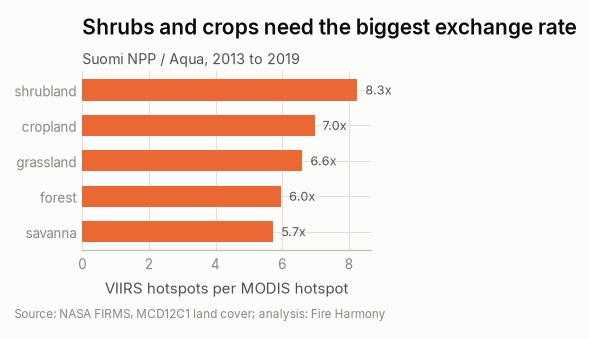

In [4]:
lc = con.execute(f'''
  SELECT s.lc_main, sum(g.n_main) FILTER (WHERE g.satellite = 'Suomi-NPP') / sum(g.n_main) FILTER (WHERE g.satellite = 'Aqua') AS ratio,
         sum(g.n_main) FILTER (WHERE g.satellite = 'Suomi-NPP') AS viirs
  FROM read_parquet({GOLD}) g JOIN '{STATIC}' s USING (cell)
  WHERE g.yr BETWEEN 2013 AND 2019 GROUP BY 1 HAVING viirs > 1e6 ORDER BY ratio''').df()
fig, ax = plt.subplots(figsize=fh.SIZE['half'])
ax.barh(lc.lc_main, lc.ratio, color=fh.SENSOR['VIIRS_SNPP'], height=0.6)
for i, v in enumerate(lc.ratio):
    ax.text(v, i, f'  {v:.1f}x', va='center', fontsize=7.5, color=fh.INK_2)
fh.clean(ax, grid_axis='x'); ax.set_xlabel('VIIRS hotspots per MODIS hotspot')
fh.title(ax, 'Shrubs and crops need the biggest exchange rate', 'Suomi NPP / Aqua, 2013 to 2019')
fh.source(fig, 'Source: NASA FIRMS, MCD12C1 land cover; analysis: Fire Harmony')
fh.save(fig, FIG / 'fig02_ratio_by_land_cover')
lc.round(2)

## 4. Fires that MODIS misses completely

Some months, a hexagon has VIIRS fires but no MODIS fire at all. A simple exchange rate turns those into zero. How much fire is that?

In [5]:
miss = con.execute(f'''
  WITH p AS (SELECT cell, yr, mo, coalesce(sum(n_main) FILTER (WHERE family = 'MODIS'), 0) m,
                    coalesce(sum(n_main) FILTER (WHERE satellite = 'Suomi-NPP'), 0) v
             FROM read_parquet({GOLD}) WHERE yr BETWEEN 2013 AND 2019 GROUP BY ALL)
  SELECT 100 * sum(v) FILTER (WHERE m = 0) / sum(v) AS pct FROM p''').fetchall()[0][0]
print(f'{miss:.1f}% of VIIRS hotspots fall in cell months where MODIS saw nothing')

8.7% of VIIRS hotspots fall in cell months where MODIS saw nothing


> **Key findings**
>
> - Per satellite, VIIRS records about eight times more hotspots than MODIS. Joining them without care creates a fake jump in 2012.
> - With the same afternoon pass, VIIRS sees about 6 times more fire than MODIS: 5 times by day and 30 times at night.
> - Almost half of what VIIRS sees is weak fire below 5 MW. MODIS almost never records such fires (below 1%).
> - The gap changes with the land: from about 5.7 times in savannas to 8.3 times in shrublands.
> - About 9% of VIIRS hotspots (2013 to 2019) fall where MODIS saw nothing that month. A single exchange rate cannot recover them, so our model also uses the fire activity around each cell and its usual season.